# 01 - Nominal Readiness (S1)

**Question this notebook answers:** under clean, healthy operating conditions, does the CRI
correctly recognize that the candidate (OFO) controller is safe to activate, without
unnecessarily obstructing it?

This notebook only *calls* functions from `cri_microgrid` -- every equation (the five
indicators, the CRI combination, the dynamic filter, the classification, safe probing) lives in
the package, not here, so the implementation stays auditable independent of any notebook.

Outputs: `results/results_S1.csv`, `Figures/Fig_CRIDashboard.pdf`, `Figures/Fig_nominal_pu.pdf`.

In [39]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from cri_microgrid.config import (PlantParams, ControllerParams, ConstraintParams, CRIParams,
                                   ProbeParams, ProfileParams, SimulationParams)
from cri_microgrid import scenarios, sim, metrics, validation, plotstyle

plotstyle.apply_style()
RESULTS_DIR = os.path.abspath("../results")
FIG_DIR = os.path.abspath("../Figures")
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

pp = PlantParams()
cp = ControllerParams()
cons = ConstraintParams()
crip = CRIParams()
probep = ProbeParams()
prof = ProfileParams()
SEED = 1

## Run S1 under the three activation strategies (paired seed, identical scenario/plant/OFO)

In [40]:
scenario = scenarios.build_S1(pp, prof, T_end=40.0)

logs = {}
for strategy in ["direct", "threshold", "cri"]:
    simp = SimulationParams(T_end=scenario.T_end, seed=SEED, strategy=strategy)
    logs[strategy] = sim.run_closed_loop(scenario, pp, cp, cons, crip, probep, simp)

log = logs["cri"]
print("Simulated", scenario.name, "-", scenario.description)
print("Steps:", len(log["t"]), " T_end:", scenario.T_end, "s   Ts:", pp.Ts, "s")

Simulated S1 - Nominal loading, clean measurements, full VSC headroom.
Steps: 2001  T_end: 40.0 s   Ts: 0.02 s


## Validation: every readiness quantity stays inside its analytically required range

In [41]:
def in_unit_interval(x, name):
    x = x[np.isfinite(x)]
    ok = np.all((x >= -1e-9) & (x <= 1.0 + 1e-9))
    print(f"{name:22s} min={x.min():.4f} max={x.max():.4f}  in [0,1]: {ok}")
    assert ok, f"{name} left [0,1]"

for name in ["RI", "CI", "SMI", "AI", "NCI", "CRI", "CRI_hat"]:
    in_unit_interval(log[name], name)

assert np.all((log["kappa"] >= crip.kappa_min - 1e-9) & (log["kappa"] <= 1.0 + 1e-9)), "kappa left [kappa_min,1]"
assert set(np.unique(log["s"]).tolist()) <= {0.0, 1.0}, "s_k must be binary"
assert np.all(np.isfinite(log["Vdc"])) and np.all(np.isfinite(log["V1"])), "non-finite plant signals"
print()
print("All readiness signals validated: bounded, finite, and correctly typed.")

RI                     min=0.0000 max=1.0000  in [0,1]: True
CI                     min=0.0000 max=0.5809  in [0,1]: True
SMI                    min=0.3793 max=0.7409  in [0,1]: True
AI                     min=0.8519 max=1.0000  in [0,1]: True
NCI                    min=0.0183 max=0.9972  in [0,1]: True
CRI                    min=0.4323 max=0.7834  in [0,1]: True
CRI_hat                min=0.3646 max=0.8335  in [0,1]: True

All readiness signals validated: bounded, finite, and correctly typed.


## Figure 1 -- CRI readiness dashboard

The signature figure of the paper: a shared operating-stress timeline, the five readiness
indicators as narrow synchronized traces, the combined CRI with its decision thresholds and
Activate/Monitor/Delay/Reject background, and the resulting activation status.

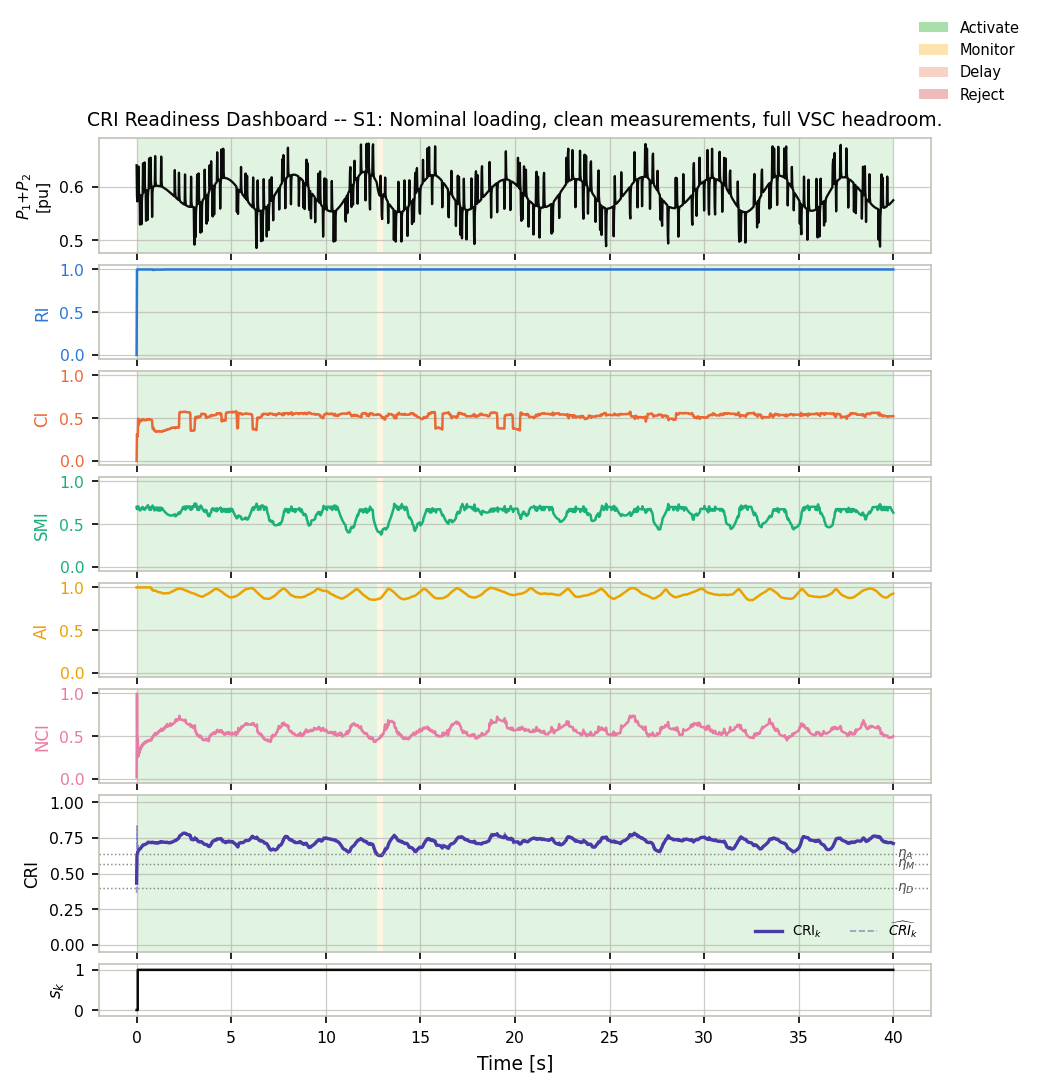

In [42]:
t = log["t"]
fig, axes = plt.subplots(8, 1, figsize=plotstyle.FIGSIZE_DASHBOARD, sharex=True,
                          gridspec_kw=dict(height_ratios=[1.1, 0.9, 0.9, 0.9, 0.9, 0.9, 1.5, 0.5], hspace=0.12))

ax = axes[0]
plotstyle.shade_classification_bg(ax, t, log["cls_code"])
ax.plot(t, log["P1_true"] + log["P2_true"], color=plotstyle.INK_PRIMARY, lw=1.1)
ax.set_ylabel("$P_1{+}P_2$\n[pu]", fontsize=7.5)
ax.set_title(f"CRI Readiness Dashboard -- {scenario.name}: {scenario.description}", fontsize=9)

indicator_names = ["RI", "CI", "SMI", "AI", "NCI"]
for i, name in enumerate(indicator_names):
    ax = axes[i + 1]
    plotstyle.shade_classification_bg(ax, t, log["cls_code"])
    ax.plot(t, log[name], color=plotstyle.INDICATOR_COLORS[name], lw=1.2)
    ax.set_ylim(-0.05, 1.05)
    ax.set_ylabel(name, fontsize=8, color=plotstyle.INDICATOR_COLORS[name])
    ax.tick_params(axis="y", labelcolor=plotstyle.INDICATOR_COLORS[name])

ax = axes[6]
plotstyle.shade_classification_bg(ax, t, log["cls_code"])
ax.plot(t, log["CRI"], color=plotstyle.INDICATOR_COLORS["CRI"], lw=1.6, label="CRI$_k$")
ax.plot(t, log["CRI_hat"], color=plotstyle.INDICATOR_COLORS["CRI"], lw=0.8, alpha=0.5, ls="--", label=r"$\widehat{CRI}_k$")
for eta, lbl in [(crip.eta_A, r"$\eta_A$"), (crip.eta_M, r"$\eta_M$"), (crip.eta_D, r"$\eta_D$")]:
    ax.axhline(eta, color=plotstyle.INK_MUTED, lw=0.7, ls=":")
    ax.text(t[-1] * 1.005, eta, lbl, fontsize=6.5, va="center", color=plotstyle.INK_SECONDARY)
ax.set_ylim(-0.05, 1.05)
ax.set_ylabel("CRI", fontsize=8)
ax.legend(loc="lower right", ncol=2, frameon=False, fontsize=6.5)

ax = axes[7]
ax.step(t, log["s"], where="post", color=plotstyle.INK_PRIMARY, lw=1.2)
ax.set_ylim(-0.15, 1.15)
ax.set_yticks([0, 1])
ax.set_ylabel("$s_k$", fontsize=8)
ax.set_xlabel("Time [s]")

handles = plotstyle.classification_legend_handles()
fig.legend(handles=handles, loc="upper right", bbox_to_anchor=(0.995, 0.995), ncol=1, frameon=False, fontsize=7)

plotstyle.savefig(fig, os.path.join(FIG_DIR, "Fig_CRIDashboard.pdf"))
plt.show()

## Figure 1 (v2) -- clarity pass

The cell above is kept exactly as-is (the standard reference version). This cell is a revised
layout addressing four issues found by inspection:

1. **No title** -- the paper caption will describe the figure; an in-figure title is redundant.
2. **Classification legend didn't match the figure.** Checking `cls_code` for this run: S1 spends
   1981/2001 samples in `Activate`, 19 in `Monitor`, 1 in `Delay`, and **0** in `Reject` -- so a
   4-color Activate/Monitor/Delay/Reject legend was showing a color (`Reject`) that never once
   appears in this particular scenario, and the background was ~99% a single solid tint anyway.
   Dropped here; kept (and legitimately useful) in the scenarios where multiple classes actually
   occur (S2, S7, S8).
3. **Five indicators, one shared legend.** Previously each indicator had its own thin stacked
   panel with only a color-coded axis label -- easy to misread as "one line" at small size. Now
   all five are overlaid on one panel with a proper 5-entry legend.
4. **Line opacity fixed at 0.98** (`LINE_ALPHA` below) so every color reads clearly against white.

Figure size is controlled by two explicit variables (`FIG_WIDTH`, `FIG_HEIGHT`) sized for a single
IEEE column (~3.5 in) -- edit those two numbers directly to resize; everything else (line widths,
font sizes, alpha) is likewise a named constant at the top of the cell for quick tuning.

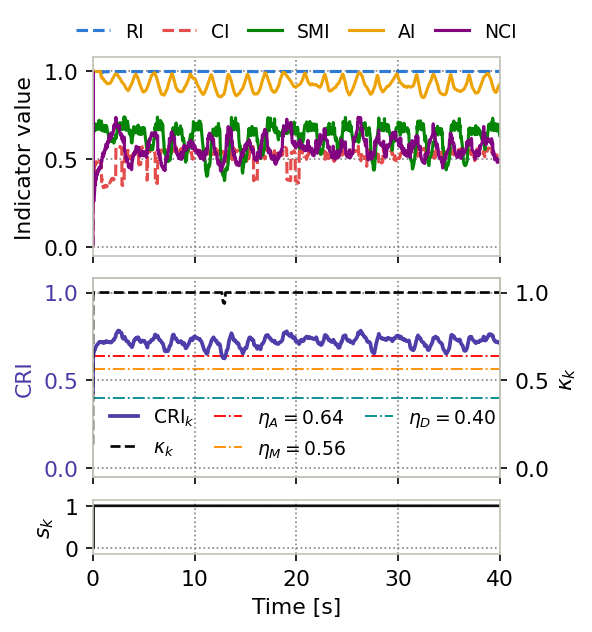

In [43]:
# ======================================================================
# Easy-to-tune figure settings
# ======================================================================

FIG_WIDTH = 3.5          # inches -- ~1 IEEE column
FIG_HEIGHT = 4.3         # inches

LINE_ALPHA = 0.98

LW_INDICATOR = 1.5
LW_CRI = 1.8
LW_KAPPA = 1.3
LW_THRESH = 0.9
LW_ACTIVATION = 1.3

FONT_AXIS = 10.5
FONT_TICK = 10.5
FONT_LEGEND = 9.0

HEIGHT_RATIOS = [2.0, 2.0, 0.55]
HSPACE = 0.15


# ======================================================================
# Grid settings
# ======================================================================

GRID_COLOR = "gray"
GRID_ALPHA = 0.98
GRID_LW = 0.80
GRID_LS = ":"


INDICATOR_STYLE = {
    "RI":  dict(color=plotstyle.CAT["blue"],   ls="--"),
    "CI":  dict(color=plotstyle.CAT["red"],    ls="--"),
    "SMI": dict(color=plotstyle.CAT["green"],  ls="-"),
    "AI":  dict(color=plotstyle.CAT["yellow"], ls="-"),
    "NCI": dict(color="purple",                 ls="-"),
}

# CRI
CRI_STYLE = dict(
    color=plotstyle.CAT["violet"],
    ls="-"
)

# Kappa -- direct Matplotlib color
KAPPA_STYLE = dict(
    color="black",
    ls="--"
)

# Decision thresholds -- each one has its own color
ETA_A_STYLE = dict(
    color="red",
    ls="-."
)

ETA_M_STYLE = dict(
    color="darkorange",
    ls="-."
)

ETA_D_STYLE = dict(
    color="darkcyan",
    ls="-."
)

# Activation status
ACTIVATION_STYLE = dict(
    color=plotstyle.INK_PRIMARY,
    ls="-"
)


# ======================================================================
# Time vector
# ======================================================================

t = log["t"]


# ======================================================================
# Create figure
# ======================================================================

fig, axes = plt.subplots(
    3,
    1,
    figsize=(FIG_WIDTH, FIG_HEIGHT),
    sharex=True,
    gridspec_kw=dict(
        height_ratios=HEIGHT_RATIOS,
        hspace=HSPACE
    )
)


# ======================================================================
# Panel 1: Five readiness indicators
# ======================================================================

ax = axes[0]

for name, style in INDICATOR_STYLE.items():
    ax.plot(
        t,
        log[name],
        color=style["color"],
        ls=style["ls"],
        lw=LW_INDICATOR,
        alpha=LINE_ALPHA,
        label=name
    )

ax.set_ylim(-0.05, 1.08)

ax.set_ylabel(
    "Indicator value",
    fontsize=FONT_AXIS
)

ax.tick_params(
    labelsize=FONT_TICK
)

# Black, clear grid
ax.grid(
    True,
    color=GRID_COLOR,
    alpha=GRID_ALPHA,
    linewidth=GRID_LW,
    linestyle=GRID_LS
)

# Indicator legend
ax.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, 1.0),
    ncol=5,
    frameon=False,
    fontsize=FONT_LEGEND,
    handlelength=1.8,
    columnspacing=1.0
)


# ======================================================================
# Panel 2: CRI + kappa + decision thresholds
# ======================================================================

ax = axes[1]


# ----------------------------------------------------------------------
# CRI
# ----------------------------------------------------------------------

l1, = ax.plot(
    t,
    log["CRI"],
    color=CRI_STYLE["color"],
    ls=CRI_STYLE["ls"],
    lw=LW_CRI,
    alpha=LINE_ALPHA,
    label=r"CRI$_k$"
)


# ----------------------------------------------------------------------
# Decision thresholds
# ----------------------------------------------------------------------

lA = ax.axhline(
    crip.eta_A,
    color=ETA_A_STYLE["color"],
    ls=ETA_A_STYLE["ls"],
    lw=LW_THRESH,
    alpha=LINE_ALPHA,
    zorder=1,
    label=rf"$\eta_A={crip.eta_A:.2f}$"
)

lM = ax.axhline(
    crip.eta_M,
    color=ETA_M_STYLE["color"],
    ls=ETA_M_STYLE["ls"],
    lw=LW_THRESH,
    alpha=LINE_ALPHA,
    zorder=1,
    label=rf"$\eta_M={crip.eta_M:.2f}$"
)

lD = ax.axhline(
    crip.eta_D,
    color=ETA_D_STYLE["color"],
    ls=ETA_D_STYLE["ls"],
    lw=LW_THRESH,
    alpha=LINE_ALPHA,
    zorder=1,
    label=rf"$\eta_D={crip.eta_D:.2f}$"
)


# ----------------------------------------------------------------------
# CRI axis formatting
# ----------------------------------------------------------------------

ax.set_ylim(-0.05, 1.08)

# No extra space is needed because the annotation arrows were removed
ax.set_xlim(
    t[0],
    t[-1]
)

ax.set_ylabel(
    "CRI",
    fontsize=FONT_AXIS,
    color=CRI_STYLE["color"]
)

ax.tick_params(
    axis="y",
    labelcolor=CRI_STYLE["color"],
    labelsize=FONT_TICK
)

ax.tick_params(
    axis="x",
    labelsize=FONT_TICK
)

# Black grid
ax.grid(
    True,
    color=GRID_COLOR,
    alpha=GRID_ALPHA,
    linewidth=GRID_LW,
    linestyle=GRID_LS
)


# ----------------------------------------------------------------------
# Kappa on right y-axis
# ----------------------------------------------------------------------

ax2 = ax.twinx()

l2, = ax2.plot(
    t,
    log["kappa"],
    color=KAPPA_STYLE["color"],
    ls=KAPPA_STYLE["ls"],
    lw=LW_KAPPA,
    alpha=LINE_ALPHA,
    label=r"$\kappa_k$"
)

ax2.set_ylim(-0.05, 1.08)

ax2.set_ylabel(
    r"$\kappa_k$",
    fontsize=FONT_AXIS,
    color=KAPPA_STYLE["color"]
)

ax2.tick_params(
    axis="y",
    labelcolor=KAPPA_STYLE["color"],
    labelsize=FONT_TICK
)

# IMPORTANT:
# Do not enable the grid on the twin axis,
# otherwise two grids overlap.
ax2.grid(False)


# ----------------------------------------------------------------------
# Combined legend:
# CRI + kappa + all three thresholds
# ----------------------------------------------------------------------

ax.legend(
    [l1, l2, lA, lM, lD],
    [
        r"CRI$_k$",
        r"$\kappa_k$",
        rf"$\eta_A={crip.eta_A:.2f}$",
        rf"$\eta_M={crip.eta_M:.2f}$",
        rf"$\eta_D={crip.eta_D:.2f}$"
    ],
    loc="lower left",
    ncol=3,
    frameon=False,
    fontsize=FONT_LEGEND,
    handlelength=1.5,
    columnspacing=1
)


# ======================================================================
# Panel 3: Activation status
# ======================================================================

ax = axes[2]

ax.step(
    t,
    log["s"],
    where="post",
    color=ACTIVATION_STYLE["color"],
    ls=ACTIVATION_STYLE["ls"],
    lw=LW_ACTIVATION,
    alpha=LINE_ALPHA
)

ax.set_ylim(-0.15, 1.15)

ax.set_yticks([0, 1])

ax.set_ylabel(
    r"$s_k$",
    fontsize=FONT_AXIS
)

ax.set_xlabel(
    "Time [s]",
    fontsize=FONT_AXIS
)

ax.tick_params(
    labelsize=FONT_TICK
)

# Black grid
ax.grid(
    True,
    color=GRID_COLOR,
    alpha=GRID_ALPHA,
    linewidth=GRID_LW,
    linestyle=GRID_LS
)


# ======================================================================
# Save and display
# ======================================================================

plotstyle.savefig(
    fig,
    os.path.join(
        FIG_DIR,
        "Fig_CRIDashboard_v2.pdf"
    )
)

plt.show()

## Figure 2 -- Nominal plant response, all in per-unit

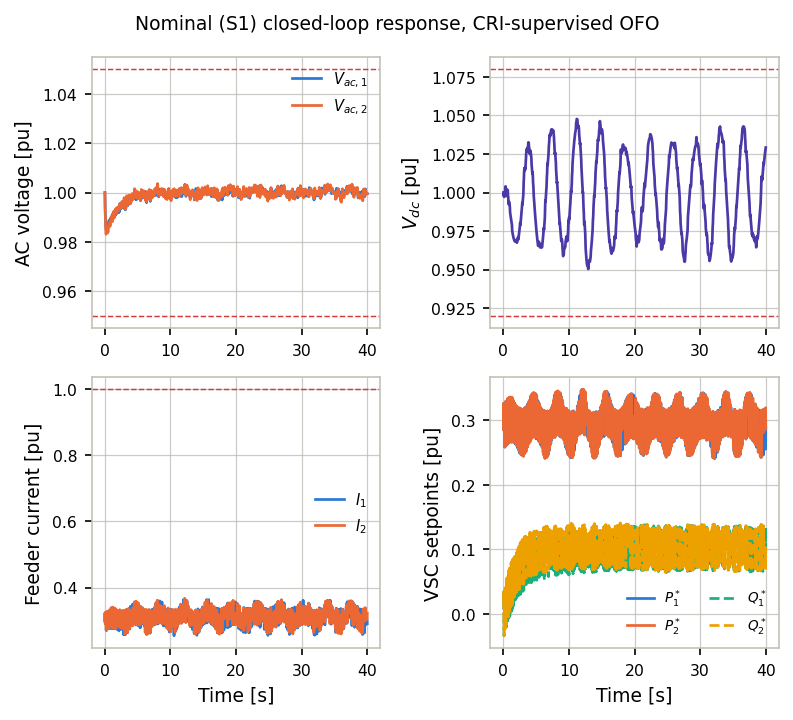

In [44]:
fig, axs = plt.subplots(2, 2, figsize=plotstyle.FIGSIZE_2x2)

ax = axs[0, 0]
ax.plot(t, log["V1"], color=plotstyle.CAT["blue"], label="$V_{ac,1}$")
ax.plot(t, log["V2"], color=plotstyle.CAT["orange"], label="$V_{ac,2}$")
ax.axhline(cons.Vac_min, color=plotstyle.STATUS["Reject"], lw=0.7, ls="--")
ax.axhline(cons.Vac_max, color=plotstyle.STATUS["Reject"], lw=0.7, ls="--")
ax.set_ylabel("AC voltage [pu]"); ax.legend(frameon=False, fontsize=7)

ax = axs[0, 1]
ax.plot(t, log["Vdc"], color=plotstyle.CAT["violet"])
ax.axhline(cons.Vdc_min, color=plotstyle.STATUS["Reject"], lw=0.7, ls="--")
ax.axhline(cons.Vdc_max, color=plotstyle.STATUS["Reject"], lw=0.7, ls="--")
ax.set_ylabel("$V_{dc}$ [pu]")

ax = axs[1, 0]
ax.plot(t, log["I1"], color=plotstyle.CAT["blue"], label="$I_1$")
ax.plot(t, log["I2"], color=plotstyle.CAT["orange"], label="$I_2$")
ax.axhline(cons.I_max, color=plotstyle.STATUS["Reject"], lw=0.7, ls="--")
ax.set_ylabel("Feeder current [pu]"); ax.set_xlabel("Time [s]"); ax.legend(frameon=False, fontsize=7)

ax = axs[1, 1]
ax.plot(t, log["P1_cmd"], color=plotstyle.CAT["blue"], label="$P_1^*$")
ax.plot(t, log["P2_cmd"], color=plotstyle.CAT["orange"], label="$P_2^*$")
ax.plot(t, log["Q1_cmd"], color=plotstyle.CAT["aqua"], label="$Q_1^*$", ls="--")
ax.plot(t, log["Q2_cmd"], color=plotstyle.CAT["yellow"], label="$Q_2^*$", ls="--")
ax.set_ylabel("VSC setpoints [pu]"); ax.set_xlabel("Time [s]"); ax.legend(frameon=False, fontsize=6.5, ncol=2)

fig.suptitle("Nominal (S1) closed-loop response, CRI-supervised OFO", fontsize=9)
plotstyle.savefig(fig, os.path.join(FIG_DIR, "Fig_nominal_pu.pdf"))
plt.show()

## Figure 2 (v2) -- clarity pass, same conventions as Fig. 1 (dashboard)

The cell above is kept as the standard reference version. This is the revised layout: explicit
`FIG_WIDTH`/`FIG_HEIGHT`, a named color+linestyle dict per line, `LINE_ALPHA=0.98`, grid on, no
title (the caption carries that in the paper). Sized for one IEEE column; a 2x2 grid is inherently
tighter per-panel than the 3-row dashboard layout, so font sizes here are a notch smaller
(`FONT_AXIS=9`, vs. 10.5 in Fig. 1) to stay legible without crowding -- both are still just
constants at the top, so bump them back up if you'd rather trade off panel breathing room.

## Strategy comparison summary and CSV export

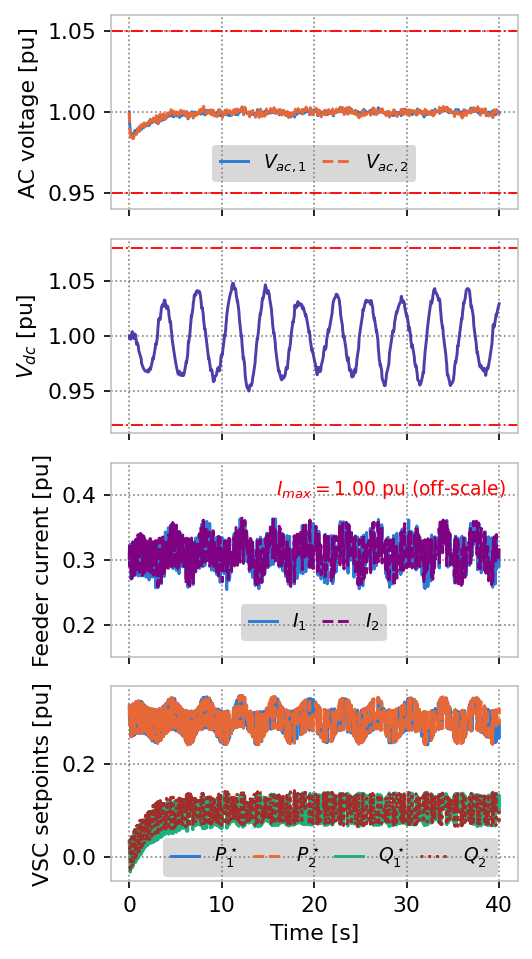

In [81]:
# ======================================================================
# Easy-to-tune figure settings
# ======================================================================

FIG_WIDTH = 3.5
FIG_HEIGHT = 7.5

LINE_ALPHA = 0.98

LW_MAIN = 1.4
LW_LIMIT = 0.9

FONT_AXIS = 10.5
FONT_TICK = 10.5
FONT_LEGEND = 9.0

HEIGHT_RATIOS = [1.0, 1.0, 1.0, 1.0]
HSPACE = 0.15


# ======================================================================
# Legend settings -- same box style for all legends
# ======================================================================

# Positions: (horizontal, vertical)
LEGEND_POS_V = (0.5, 0.38)       # Row 1: AC voltages
LEGEND_POS_I = (0.5, 0.32)       # Row 3: feeder currents
LEGEND_POS_U = (0.54, 0.27)       # Row 4: VSC setpoints

# Same box appearance for all legends
LEGEND_FRAME = True
LEGEND_FRAME_ALPHA = 0.3
LEGEND_FACE_COLOR = "gray"
LEGEND_EDGE_COLOR = "none"

LEGEND_COLUMN_SPACING = 0.8
LEGEND_HANDLE_LENGTH = 1.5


# ======================================================================
# Grid settings
# ======================================================================

GRID_COLOR = "gray"
GRID_ALPHA = 0.98
GRID_LW = 0.80
GRID_LS = ":"


# ======================================================================
# Every line's color + linestyle
# ======================================================================

V_STYLE = {
    "V1": dict(
        color=plotstyle.CAT["blue"],
        ls="-",
        label=r"$V_{ac,1}$"
    ),

    "V2": dict(
        color=plotstyle.CAT["orange"],
        ls="--",
        label=r"$V_{ac,2}$"
    ),
}


VDC_STYLE = dict(
    color=plotstyle.CAT["violet"],
    ls="-",
    label=r"$V_{dc}$"
)


I_STYLE = {
    "I1": dict(
        color=plotstyle.CAT["blue"],
        ls="-",
        label=r"$I_1$"
    ),

    "I2": dict(
        color="purple",
        ls="--",
        label=r"$I_2$"
    ),
}


U_STYLE = {
    "P1_cmd": dict(
        color=plotstyle.CAT["blue"],
        ls="-",
        label=r"$P_1^\star$"
    ),

    "P2_cmd": dict(
        color=plotstyle.CAT["orange"],
        ls="--",
        label=r"$P_2^\star$"
    ),

    "Q1_cmd": dict(
        color=plotstyle.CAT["aqua"],
        ls="-",
        label=r"$Q_1^\star$"
    ),

    "Q2_cmd": dict(
        color="brown",
        ls=":",
        label=r"$Q_2^\star$"
    ),
}


# ======================================================================
# Hard operational limits
# ======================================================================

LIMIT_COLOR = "red"

LIMIT_STYLE = dict(
    color=LIMIT_COLOR,
    ls="-.",
    lw=LW_LIMIT
)


# ======================================================================
# Grid helper
# ======================================================================

def style_grid(ax):
    ax.grid(
        True,
        color=GRID_COLOR,
        alpha=GRID_ALPHA,
        linewidth=GRID_LW,
        linestyle=GRID_LS
    )


# ======================================================================
# Time vector
# ======================================================================

t = log["t"]


# ======================================================================
# Create figure
# ======================================================================

fig, axes = plt.subplots(
    4,
    1,
    figsize=(FIG_WIDTH, FIG_HEIGHT),
    sharex=True,
    gridspec_kw=dict(
        height_ratios=HEIGHT_RATIOS,
        hspace=HSPACE
    )
)


# ======================================================================
# Row 1: AC bus voltages
# ======================================================================

ax = axes[0]

for key, style in V_STYLE.items():
    ax.plot(
        t,
        log[key],
        color=style["color"],
        ls=style["ls"],
        lw=LW_MAIN,
        alpha=LINE_ALPHA,
        label=style["label"]
    )

# Operational voltage limits
ax.axhline(
    cons.Vac_min,
    color=LIMIT_STYLE["color"],
    ls=LIMIT_STYLE["ls"],
    lw=LIMIT_STYLE["lw"],
    alpha=LINE_ALPHA
)

ax.axhline(
    cons.Vac_max,
    color=LIMIT_STYLE["color"],
    ls=LIMIT_STYLE["ls"],
    lw=LIMIT_STYLE["lw"],
    alpha=LINE_ALPHA
)

ax.set_ylim(0.94, 1.06)

ax.set_ylabel(
    "AC voltage [pu]",
    fontsize=FONT_AXIS
)

ax.tick_params(
    labelsize=FONT_TICK
)

style_grid(ax)

# Same legend box style
ax.legend(
    frameon=LEGEND_FRAME,
    framealpha=LEGEND_FRAME_ALPHA,
    facecolor=LEGEND_FACE_COLOR,
    edgecolor=LEGEND_EDGE_COLOR,
    fontsize=FONT_LEGEND,
    ncol=2,
    columnspacing=LEGEND_COLUMN_SPACING,
    handlelength=LEGEND_HANDLE_LENGTH,
    loc="upper center",
    bbox_to_anchor=LEGEND_POS_V
)


# ======================================================================
# Row 2: DC-link voltage
# ======================================================================

ax = axes[1]

ax.plot(
    t,
    log["Vdc"],
    color=VDC_STYLE["color"],
    ls=VDC_STYLE["ls"],
    lw=LW_MAIN,
    alpha=LINE_ALPHA,
    label=VDC_STYLE["label"]
)

# Operational DC-voltage limits
ax.axhline(
    cons.Vdc_min,
    color=LIMIT_STYLE["color"],
    ls=LIMIT_STYLE["ls"],
    lw=LIMIT_STYLE["lw"],
    alpha=LINE_ALPHA
)

ax.axhline(
    cons.Vdc_max,
    color=LIMIT_STYLE["color"],
    ls=LIMIT_STYLE["ls"],
    lw=LIMIT_STYLE["lw"],
    alpha=LINE_ALPHA
)

ax.set_ylabel(
    r"$V_{dc}$ [pu]",
    fontsize=FONT_AXIS
)

ax.tick_params(
    labelsize=FONT_TICK
)

style_grid(ax)


# ======================================================================
# Row 3: Feeder currents
# ======================================================================

ax = axes[2]

for key, style in I_STYLE.items():
    ax.plot(
        t,
        log[key],
        color=style["color"],
        ls=style["ls"],
        lw=LW_MAIN,
        alpha=LINE_ALPHA,
        label=style["label"]
    )

ax.set_ylim(0.15, 0.45)

# Current limit is outside visible range
ax.text(
    0.97,
    0.92,
    rf"$I_{{max}}={cons.I_max:.2f}$ pu (off-scale)",
    transform=ax.transAxes,
    fontsize=FONT_LEGEND,
    ha="right",
    va="top",
    color=LIMIT_COLOR
)

ax.set_ylabel(
    "Feeder current [pu]",
    fontsize=FONT_AXIS
)

ax.tick_params(
    labelsize=FONT_TICK
)

style_grid(ax)

# Same legend box style
ax.legend(
    frameon=LEGEND_FRAME,
    framealpha=LEGEND_FRAME_ALPHA,
    facecolor=LEGEND_FACE_COLOR,
    edgecolor=LEGEND_EDGE_COLOR,
    fontsize=FONT_LEGEND,
    ncol=2,
    columnspacing=LEGEND_COLUMN_SPACING,
    handlelength=LEGEND_HANDLE_LENGTH,
    loc="upper center",
    bbox_to_anchor=LEGEND_POS_I
)


# ======================================================================
# Row 4: VSC setpoints
# ======================================================================

ax = axes[3]

for key, style in U_STYLE.items():
    ax.plot(
        t,
        log[key],
        color=style["color"],
        ls=style["ls"],
        lw=LW_MAIN,
        alpha=LINE_ALPHA,
        label=style["label"]
    )

ax.set_ylabel(
    "VSC setpoints [pu]",
    fontsize=FONT_AXIS
)

ax.set_xlabel(
    "Time [s]",
    fontsize=FONT_AXIS
)

ax.tick_params(
    labelsize=FONT_TICK
)

style_grid(ax)

# Same legend box style
ax.legend(
    frameon=LEGEND_FRAME,
    framealpha=LEGEND_FRAME_ALPHA,
    facecolor=LEGEND_FACE_COLOR,
    edgecolor=LEGEND_EDGE_COLOR,
    fontsize=FONT_LEGEND,
    ncol=4,
    columnspacing=LEGEND_COLUMN_SPACING,
    handlelength=LEGEND_HANDLE_LENGTH,
    loc="upper center",
    bbox_to_anchor=LEGEND_POS_U
)


# ======================================================================
# Save and display
# ======================================================================

plotstyle.savefig(
    fig,
    os.path.join(
        FIG_DIR,
        "Fig_nominal_pu_v2.pdf"
    )
)

plt.show()

In [8]:
rows = []
for strategy, lg in logs.items():
    z = validation.compute_unsafe_truth(lg, cons, noise_level_pct=scenario.noise_cfg.get("level_pct", 0.0))
    rows.append(dict(
        strategy=strategy,
        E_V=metrics.voltage_deviation(lg["V1"], lg["V2"], pp.Vac_nom),
        E_I=metrics.current_violation(lg["I1"], lg["I2"], cons.I_max),
        E_dc=metrics.dc_voltage_deviation(lg["Vdc"], pp.Vdc_nom),
        N_FA=metrics.false_activation_count(lg["s"], z),
        unsafe_active_fraction=metrics.unsafe_active_fraction(lg["s"], z),
        T_on_s=metrics.active_duration(lg["s"], pp.Ts),
        safe_availability_pct=metrics.safe_availability_pct(lg["s"], z),
        mean_CRI=float(np.mean(lg["CRI"])),
        mean_kappa=float(np.mean(lg["kappa"])),
    ))
summary = pd.DataFrame(rows).set_index("strategy")
display(summary.round(4))
summary.to_csv(os.path.join(RESULTS_DIR, "results_S1_strategy_summary.csv"))

,E_V,E_I,E_dc,N_FA,unsafe_active_fraction,T_on_s,safe_availability_pct,mean_CRI,mean_kappa
strategy,,,,,,,,,
direct,0.0018,0.0,0.0175,0,0.0,40.02,100.0000,1.0000,1.0000
threshold,0.0018,0.0,0.0175,0,0.0,40.02,100.0000,1.0000,1.0000
cri,0.0023,0.0,0.0235,0,0.0,39.96,99.8501,0.7209,0.9992


In [9]:
cols = ["t", "RI", "CI", "SMI", "AI", "NCI", "CRI", "CRI_hat", "beta", "kappa", "s", "cls_code",
        "dt_flag", "V1", "V2", "Vdc", "I1", "I2", "P_POI", "Q_POI", "probe_bar", "probe_norm",
        "P1_cmd", "Q1_cmd", "P2_cmd", "Q2_cmd"]
df = pd.DataFrame({c: log[c] for c in cols})
df.to_csv(os.path.join(RESULTS_DIR, "results_S1.csv"), index=False)
print("Saved", len(df), "rows to results_S1.csv")
df.head()

Saved 2001 rows to results_S1.csv


,t,RI,CI,SMI,AI,NCI,CRI,CRI_hat,beta,kappa,...,I1,I2,P_POI,Q_POI,probe_bar,probe_norm,P1_cmd,Q1_cmd,P2_cmd,Q2_cmd
0,0.00,0.000000,0.000000,0.700000,1.0,0.018316,0.432289,0.364579,0.500000,0.134539,...,0.300000,0.300000,0.000000,-0.200000,0.035,0.035,0.325000,0.035000,0.325000,0.035000
1,0.02,0.999359,0.313475,0.676654,1.0,0.997237,0.632907,0.833525,0.500000,0.970446,...,0.323132,0.323346,0.040556,-0.143221,0.000,0.000,0.284631,0.014836,0.284631,0.016814
2,0.04,1.000000,0.283863,0.705849,1.0,0.318203,0.636925,0.669692,0.109218,0.987186,...,0.293799,0.294151,-0.017272,-0.163604,0.000,0.000,0.285170,0.019566,0.285170,0.022108
3,0.06,1.000000,0.290636,0.710049,1.0,0.466986,0.650664,0.708825,0.191092,1.000000,...,0.289465,0.289951,-0.027320,-0.159324,0.000,0.000,0.290147,0.000605,0.290202,0.000741
4,0.08,0.999948,0.492629,0.707219,1.0,0.260322,0.656882,0.676499,0.240669,1.000000,...,0.292368,0.292781,-0.021099,-0.191225,0.000,0.000,0.290289,0.001067,0.290377,0.001305


## Takeaway

Under nominal, healthy conditions the CRI-supervised strategy matches Direct/Threshold on every
control metric while never trading away safety margin -- it activates the candidate OFO
controller essentially continuously (`s_k=1`), with zero false activations, confirming the
framework does not unnecessarily obstruct good control (Sec. VII-A of the manuscript).